In [1]:
import numpy as np

X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

Y = np.array([0, 1, 1, 0])

print(X)
print(Y)

[[0 0]
 [0 1]
 [1 0]
 [1 1]]
[0 1 1 0]


In [5]:
weights = np.zeros(2)
bias = 0.0
lr = 0.1

In [6]:
for epoch in range(20):
    for i in range(len(X)):
        z = np.dot(X[i], weights) + bias

        if z > 0:
            prediction = 1
        else:
            prediction = 0

        error = Y[i] - prediction

        weights = weights + lr * error * X[i]
        bias = bias + lr * error

In [7]:
correct = 0

for i in range(len(X)):
    z = np.dot(X[i], weights) + bias

    if z > 0:
        prediction = 1
    else:
        prediction = 0

    print("Input:", X[i], "Expected:", Y[i],
          "Predicted:", prediction)

    if prediction == Y[i]:
        correct += 1

print("Correct predictions:", correct, "out of 4")

Input: [0 0] Expected: 0 Predicted: 1
Input: [0 1] Expected: 1 Predicted: 1
Input: [1 0] Expected: 1 Predicted: 0
Input: [1 1] Expected: 0 Predicted: 0
Correct predictions: 2 out of 4


In [8]:
print("Final weights:", weights)
print("Final bias:", bias)

Final weights: [-0.1  0. ]
Final bias: 0.1


In [23]:
import numpy as np

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

# Initialize weights and biases
W1 = np.random.randn(2, 2)
b1 = np.zeros((1, 2))

W2 = np.random.randn(2, 1)
b2 = np.zeros((1, 1))

lr = 0.5

# Train the network
for epoch in range(10000):

    hidden = sigmoid(np.dot(X, W1) + b1)
    output = sigmoid(np.dot(hidden, W2) + b2)

    error = output - Y.reshape(-1, 1)

    d_output = error * output * (1 - output)
    d_hidden = np.dot(d_output, W2.T) * hidden * (1 - hidden)

    W2 -= lr * np.dot(hidden.T, d_output) / 4
    b2 -= lr * np.mean(d_output, axis=0, keepdims=True)

    W1 -= lr * np.dot(X.T, d_hidden) / 4
    b1 -= lr * np.mean(d_hidden, axis=0, keepdims=True)

print("Training completed")

Training completed


In [24]:
hidden = sigmoid(np.dot(X, W1) + b1)
output = sigmoid(np.dot(hidden, W2) + b2)

correct = 0

for i in range(4):
    prediction = int(output[i][0] >= 0.5)

    print(X[i], "Expected:", Y[i],
          "Predicted:", prediction)

    if prediction == Y[i]:
        correct += 1

print("Correct predictions:", correct, "out of 4")

[0 0] Expected: 0 Predicted: 0
[0 1] Expected: 1 Predicted: 1
[1 0] Expected: 1 Predicted: 1
[1 1] Expected: 0 Predicted: 0
Correct predictions: 4 out of 4


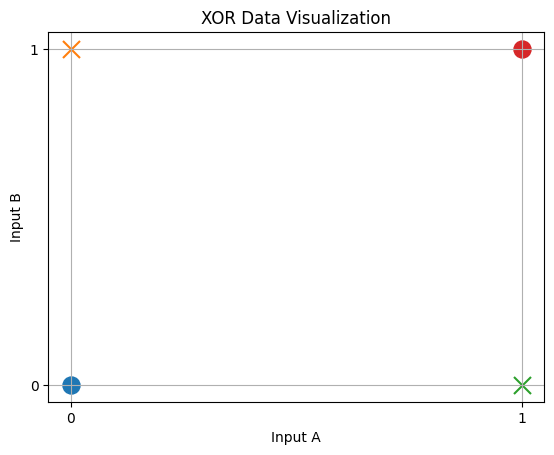

In [25]:
import matplotlib.pyplot as plt

for i in range(len(X)):
    if Y[i] == 0:
        plt.scatter(X[i][0], X[i][1], marker="o", s=150)
    else:
        plt.scatter(X[i][0], X[i][1], marker="x", s=150)

plt.xlabel("Input A")
plt.ylabel("Input B")
plt.title("XOR Data Visualization")
plt.xticks([0, 1])
plt.yticks([0, 1])
plt.grid(True)
plt.show()

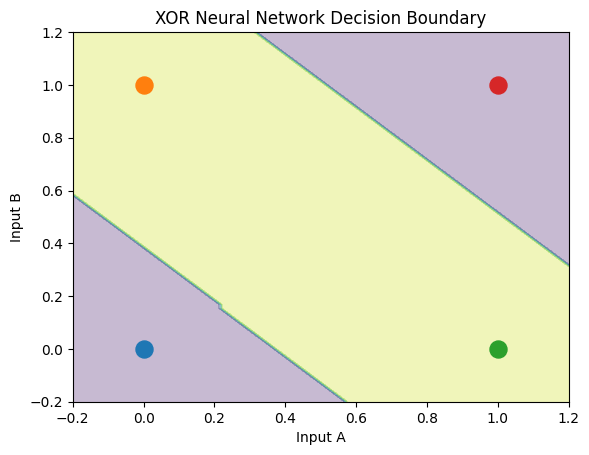

In [26]:
# Create points for the graph
xx, yy = np.meshgrid(
    np.linspace(-0.2, 1.2, 100),
    np.linspace(-0.2, 1.2, 100)
)

points = np.c_[xx.ravel(), yy.ravel()]

# Predict the output for each point
hidden = sigmoid(np.dot(points, W1) + b1)
output = sigmoid(np.dot(hidden, W2) + b2)

Z = (output >= 0.5).astype(int)
Z = Z.reshape(xx.shape)

# Plot the decision boundary
plt.contourf(xx, yy, Z, alpha=0.3)

for i in range(len(X)):
    plt.scatter(X[i][0], X[i][1], s=150)

plt.xlabel("Input A")
plt.ylabel("Input B")
plt.title("XOR Neural Network Decision Boundary")
plt.show()

In [28]:
%%writefile app.py
import streamlit as st
import numpy as np
import matplotlib.pyplot as plt

st.title("XOR Neural Network Visualizer")
st.write("A simple application to understand how a neural network solves XOR.")

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
Y = np.array([0, 1, 1, 0])

def sigmoid(x):
    return 1 / (1 + np.exp(-np.clip(x, -500, 500)))

np.random.seed(42)

W1 = np.random.randn(2, 2)
b1 = np.zeros((1, 2))
W2 = np.random.randn(2, 1)
b2 = np.zeros((1, 1))

lr = 0.5

for epoch in range(10000):
    hidden = sigmoid(np.dot(X, W1) + b1)
    output = sigmoid(np.dot(hidden, W2) + b2)

    error = output - Y.reshape(-1, 1)
    d_output = error * output * (1 - output)
    d_hidden = np.dot(d_output, W2.T) * hidden * (1 - hidden)

    W2 -= lr * np.dot(hidden.T, d_output) / 4
    b2 -= lr * np.mean(d_output, axis=0, keepdims=True)
    W1 -= lr * np.dot(X.T, d_hidden) / 4
    b1 -= lr * np.mean(d_hidden, axis=0, keepdims=True)

hidden = sigmoid(np.dot(X, W1) + b1)
output = sigmoid(np.dot(hidden, W2) + b2)
predictions = (output >= 0.5).astype(int).flatten()

st.subheader("XOR Predictions")

for i in range(4):
    st.write(
        f"Input: {X[i].tolist()} | "
        f"Expected: {Y[i]} | "
        f"Predicted: {predictions[i]}"
    )

correct = np.sum(predictions == Y)
st.metric("Correct Predictions", f"{correct}/4")

st.subheader("Decision Boundary")

xx, yy = np.meshgrid(
    np.linspace(-0.2, 1.2, 100),
    np.linspace(-0.2, 1.2, 100)
)

points = np.c_[xx.ravel(), yy.ravel()]
hidden = sigmoid(np.dot(points, W1) + b1)
output = sigmoid(np.dot(hidden, W2) + b2)
Z = (output >= 0.5).astype(int).reshape(xx.shape)

fig, ax = plt.subplots()
ax.contourf(xx, yy, Z, alpha=0.3)

for i in range(4):
    ax.scatter(X[i][0], X[i][1], s=100)

ax.set_xlabel("Input A")
ax.set_ylabel("Input B")
ax.set_title("XOR Decision Boundary")

st.pyplot(fig)

Overwriting app.py


In [29]:
%%writefile requirements.txt
streamlit
numpy
matplotlib

Writing requirements.txt


In [30]:
import os

print(os.listdir())

['.config', 'app.py', 'requirements.txt', 'sample_data']


In [31]:
from google.colab import files

files.download("app.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [32]:
from google.colab import files

files.download("requirements.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>